# K-Means Clustering from Scratch — Iris Dataset

A from-scratch K-Means implementation (NumPy only), applied to the petal length/width features of the Iris dataset. Explores the effect of `k` and of centroid initialization on the resulting clusters.


In [5]:
class CustomKMeans:
    def __init__(self, n_clusters, max_iters=100, random_state=42):
        self.n_clusters = n_clusters
        self.max_iters = max_iters
        self.random_state = random_state
        self.centroids = None
        self.labels = None

    def fit(self, X):
        np.random.seed(self.random_state)
        # Step 1: Initialize random centroids 
        random_idx = np.random.choice(X.shape[0], self.n_clusters, replace=False)
        self.centroids = X[random_idx]
        
        for _ in range(self.max_iters):
            # Step 2: Assign clusters bar asase kamtarin fasele ( Euclidean Distance)
            distances = np.linalg.norm(X[:, np.newaxis] - self.centroids, axis=2)
            old_labels = self.labels
            self.labels = np.argmin(distances, axis=1)
            
            # Convergence Check
            if old_labels is not None and np.all(old_labels == self.labels):
                break
                
            # Step 3: Update markaze clustera ba mean 
            new_centroids = np.array([
                X[self.labels == k].mean(axis=0) if np.any(self.labels == k) else self.centroids[k]
                for k in range(self.n_clusters)
            ])
            self.centroids = new_centroids


## Loading the Dataset & Selecting Features

In [6]:
iris = load_iris()
X_iris = iris.data[:, [2, 3]]

## Testing Different K Values and Initializations

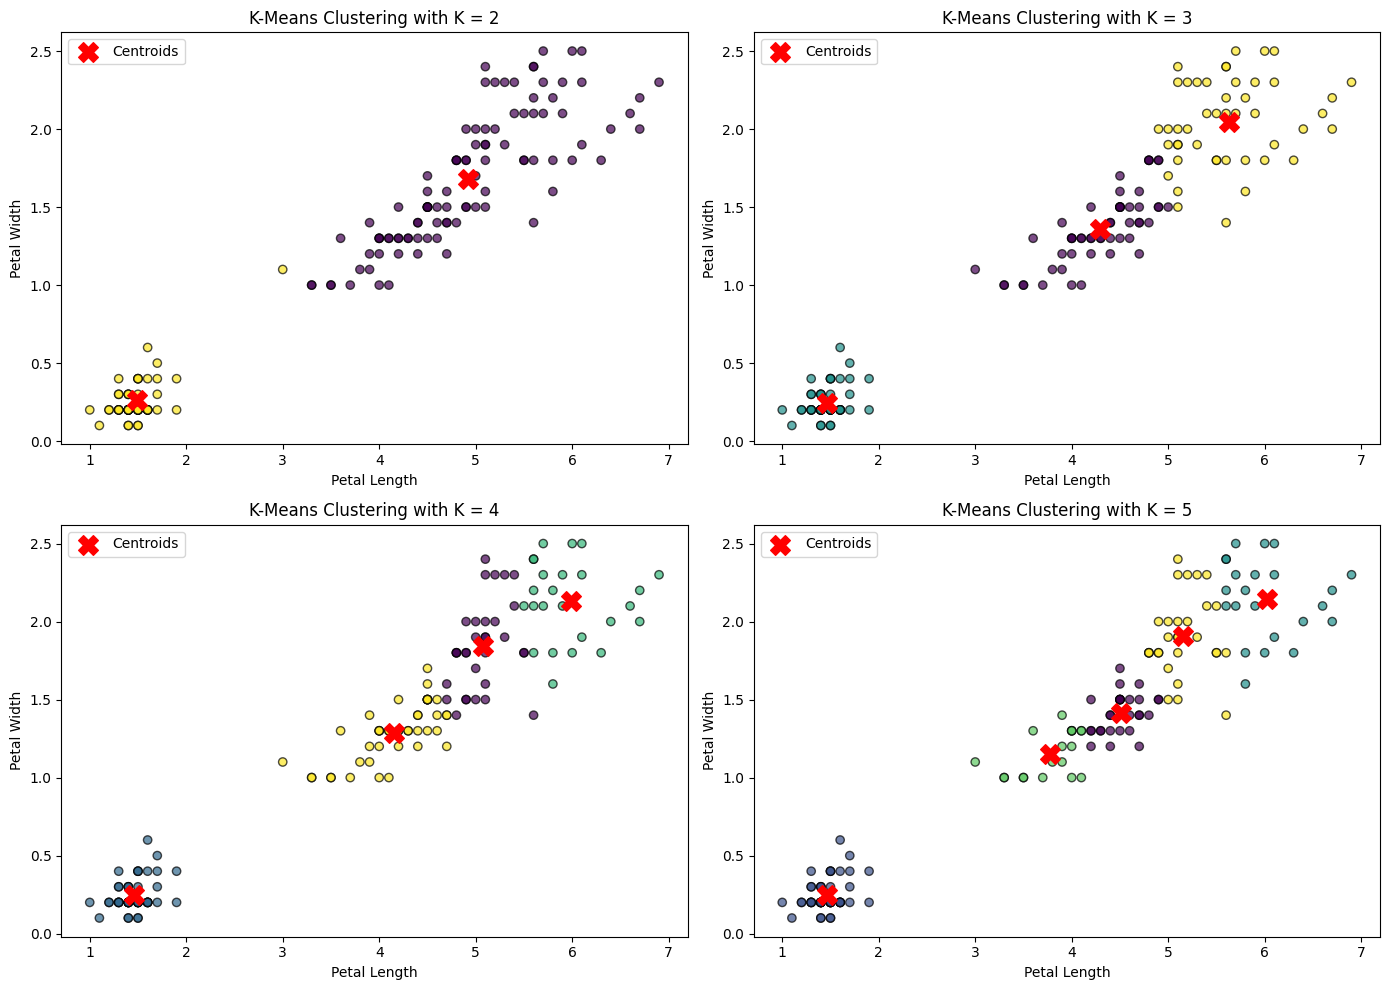

In [7]:
k_values = [2, 3, 4, 5]
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.ravel()

for i, k in enumerate(k_values):
    kmeans = CustomKMeans(n_clusters=k, random_state=42)
    kmeans.fit(X_iris)
    
    # Plot data clusters
    axes[i].scatter(X_iris[:, 0], X_iris[:, 1], c=kmeans.labels, cmap='viridis', alpha=0.7, edgecolors='k')
    # Plot calculated centroids
    axes[i].scatter(kmeans.centroids[:, 0], kmeans.centroids[:, 1], c='red', marker='X', s=200, label='Centroids')
    
    axes[i].set_title(f"K-Means Clustering with K = {k}")
    axes[i].set_xlabel("Petal Length")
    axes[i].set_ylabel("Petal Width")
    axes[i].legend()

plt.tight_layout()
plt.show()


## Effect of Centroid Initialization

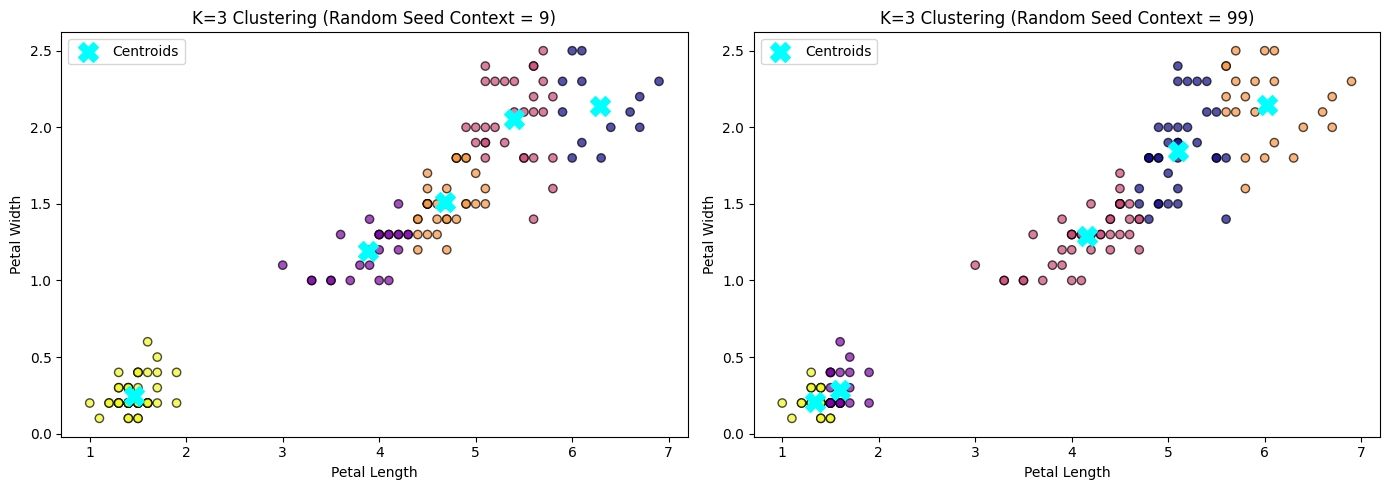

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
seeds = [9, 99] 

for i, seed in enumerate(seeds):
    kmeans_init = CustomKMeans(n_clusters=5, random_state=seed)
    kmeans_init.fit(X_iris)
    
    axes[i].scatter(X_iris[:, 0], X_iris[:, 1], c=kmeans_init.labels, cmap='plasma', alpha=0.7, edgecolors='k')
    axes[i].scatter(kmeans_init.centroids[:, 0], kmeans_init.centroids[:, 1], c='cyan', marker='X', s=200, label='Centroids')
    axes[i].set_title(f"K=3 Clustering (Random Seed Context = {seed})")
    axes[i].set_xlabel("Petal Length")
    axes[i].set_ylabel("Petal Width")
    axes[i].legend()

plt.tight_layout()
plt.show()

### Effect of the Number of Clusters ($k$)

**$k = 2$ (under-clustering):** the algorithm is forced to split the data into two large
groups. Since *setosa* is cleanly separated from the other two species, it gets its own
cluster, while *versicolor* and *virginica* — forced together — get merged into a single
cluster. The structural differences within that merged group are lost, and within-cluster
variance goes way up.

**$k = 3$ (optimal fit):** matches the true biological structure of the Iris dataset,
which contains exactly 3 species. This produces the most stable and sensible boundaries:
*setosa* is fully isolated, and the boundary between the other two species has the lowest
possible error.

**$k = 4$ and $k = 5$ (over-clustering):** forcing the algorithm to find more clusters
than the data naturally supports causes it to artificially slice dense, coherent groups
based on purely geometric criteria rather than any real structure. This reduces
interpretability and produces boundaries with no intuitive or structural meaning.


### Effect of Centroid Initialization (Seed)

Standard K-Means is highly sensitive to the initial centroid placement, since it isn't a
gradient-based optimizer — it's a greedy algorithm that easily gets stuck in local minima.
On the Iris dataset, this shows up in two ways:

**Stability at the optimal $k=3$:** in general, changing the `random_state` (seed) can
completely change the resulting clusters. But because *setosa* is so cleanly separated
from the rest of the data, there's a strong "geometric pull" in the data itself. At
$k=3$, the algorithm tends to converge to the same global minimum regardless of the seed,
showing very stable behavior.

**Local minima at non-optimal $k$ (e.g. $k > 4$):** the real impact of initialization
shows up once we push past the data's natural structure (e.g. $k=5$, or adding noise).
With no clear structure to converge toward, different starting points cause the algorithm
to settle into different valleys of the cost function. Cluster boundaries shift
noticeably, and the model's behavior becomes unpredictable and seed-dependent.
